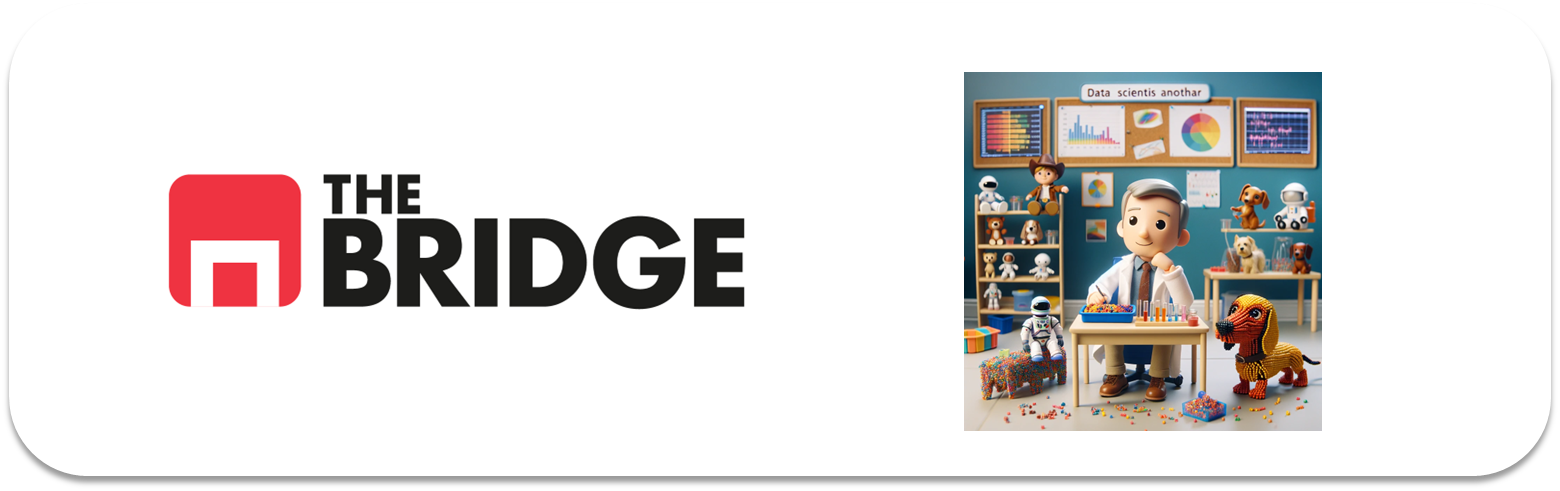

## PRACTICA OBLIGATORIA: ANÁLISIS UNIVARIANTE

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook. Te dejo una que vas a necesitar sí o sí

In [1]:

import seaborn as sns
import pandas as pd
import numpy as np


### #1 Preparación


### #1.1


Carga en un dataframe los datos del titanic a partir de un dataset de seaborn. Para ello:

* ejecuta ```python sns.get_dataset_names()```
* localiza el nombre que puede ser el adecuado para el ejercicio
* Asigna la salida de ```sns.load_dataset(<nombre_del_dataset>)``` a una variable "df_titanic"

In [2]:

sns.get_dataset_names()  # libreria que contiene datasets


['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [3]:
df_titanic = sns.load_dataset("titanic")
df_titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### #1.2

Muestra una porción del dataset ("df_titanic") y su info general. ¿Hay nulos?

In [4]:
df_titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
df_titanic.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


### #1.3

Obtén el porcentaje de nulos y decide que hacer con las columnas con nulos y ejecútalo. Además deshazte de la columna "parch" que no la emplearemos.

In [7]:
# porcentaje de nulos

porc_nulos = (df_titanic.isnull().mean() * 100)
porc_nulos[porc_nulos > 0].sort_values(ascending=False)
# ascending=False: orden de mayor a menor (descendente) - visualizacion

deck           77.216611
age            19.865320
embarked        0.224467
embark_town     0.224467
dtype: float64

In [8]:
# eliminar columna parch

df_titanic = df_titanic.drop(columns=["parch"])
df_titanic

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [125]:
# porc_nulos[porc_nulos > 0].sort_values(ascending=False)
# recordatorio para "limpiar" datos -->

In [9]:

# deck - cubierta - letra de la cubierta del camarote (77 % nulos) alto nº nulos
# embark_town: repite informacion - embarked 

df_titanic = df_titanic.drop(columns=["deck", "embark_town"])


# embarked: 2 nulos --> rellenar con la moda (ciudad más frecuente) [0] 1 elemento

df_titanic["embarked"] = df_titanic["embarked"].fillna(df_titanic["embarked"].mode()[0])


# age: 20 % de nulos --> mediana grupo (man / woman / child)
# con transform devuelve, para cada fila, la mediana de edad de su grupo

mediana_por_grupo = df_titanic.groupby("who")["age"].transform("median")

df_titanic["age"] = df_titanic["age"].fillna(mediana_por_grupo)



df_titanic.isnull().sum()       # comprobación: nulos tras "limpiar" datos

survived      0
pclass        0
sex           0
age           0
sibsp         0
fare          0
embarked      0
class         0
who           0
adult_male    0
alive         0
alone         0
dtype: int64

### #1.4
Sobre el dataset "limpio". Rellena la tabla de descripción (muy breve) de lo que es cada columna en función de su nombre y los valores. Para ayudarte:
* Se trata del dataset que reune lo más parecido a un manifiesto de supervivientes y fallecidos en el viaje.
* sibsp: Es el numero de familiares que viajan con la persona indicada en el manifiesto (lista de pasajeros)
* embarked: Es la incial de la letra de la ciudad donde embarcó la persona.


In [10]:
df_titanic

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,alive,alone
0,0,3,male,22.0,1,7.2500,S,Third,man,True,no,False
1,1,1,female,38.0,1,71.2833,C,First,woman,False,yes,False
2,1,3,female,26.0,0,7.9250,S,Third,woman,False,yes,True
3,1,1,female,35.0,1,53.1000,S,First,woman,False,yes,False
4,0,3,male,35.0,0,8.0500,S,Third,man,True,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,S,Second,man,True,no,True
887,1,1,female,19.0,0,30.0000,S,First,woman,False,yes,True
888,0,3,female,30.0,1,23.4500,S,Third,woman,False,no,False
889,1,1,male,26.0,0,30.0000,C,First,man,True,yes,True


| Columna/Variable | Descripción |
| ---------------- | ----------- |
| `survived` | Si el pasajero sobrevivió (**1**) o murió (**0**) |
| `pclass` | Clase del billete en número: 1 = primera, 2 = segunda, 3 = tercera |
| `sex` | Sexo del pasajero (`male` / `female`)  |
| `age` | Edad en años (los bebés tienen decimales, p. ej. 0,42) |
| `sibsp` | Número de familiares que viajan (hermanos - conyuges)|
| `fare` | Precio pagado por el billete |
| `embarked` | Ciudad de embarque (S, C, Q) |
| `class` | Clase del billete en texto (`First`, `Second`, `Third`); mismo dato que `pclass` |
| `who` | Tipo de pasajero: hombre (`man`), mujer (`woman`) o niño/a (`child`) |
| `adult_male` | Si es un hombre adulto (True/False) |
| `alive` | Si sobrevivió en texto (`yes` / `no`); mismo dato que `survived` |
| `alone` | Si viajaba solo, sin familiares (True/False) |

### #1.5

Busca en internet las tres ciudades que visitó el Titanic antes de poner rumbo a su destino y llegar a alta mar. Cambia las iniciales por esos valores.

In [11]:
ciudades = {"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}  # = {}
df_titanic["embarked"] = df_titanic["embarked"].map(ciudades)  # map {clave:valor} cambia
df_titanic["embarked"].value_counts()  # ver cuantas veces aparece el valor cambiado el nombre


embarked
Southampton    646
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [129]:
df_titanic

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,alive,alone
0,0,3,male,22.0,1,7.2500,Southampton,Third,man,True,no,False
1,1,1,female,38.0,1,71.2833,Cherbourg,First,woman,False,yes,False
2,1,3,female,26.0,0,7.9250,Southampton,Third,woman,False,yes,True
3,1,1,female,35.0,1,53.1000,Southampton,First,woman,False,yes,False
4,0,3,male,35.0,0,8.0500,Southampton,Third,man,True,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,Southampton,Second,man,True,no,True
887,1,1,female,19.0,0,30.0000,Southampton,First,woman,False,yes,True
888,0,3,female,30.0,1,23.4500,Southampton,Third,woman,False,no,False
889,1,1,male,26.0,0,30.0000,Cherbourg,First,man,True,yes,True


### #2 Análisis

Sabiendo que el objetivo de nuestro análisis es hacer un estudio de la superviviencia y mortalidad en el viaje... Haz un análisis univariante completo y ordenado de las siguientes variables:
["survived","who","age","fare","class","embarked","alone"]
Nota: Si quieres añadir más, perfecto.

Separa el análisis en categóricas (incluyendo binarias) y numéricas. Muestra valores, gráficas y conclusiones/observaciones (2 o 3 por variable)

### #2.1 Categóricas

In [12]:
# importado 

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones de visualización (fichero bootcampviztools.py)
from bootcampviztools import pinta_distribucion_categoricas, plot_combined_graphs

In [13]:
# funcion

def frecuencias(df, columna_categorica, porcentaje=True):
    frec_abs = df[columna_categorica].value_counts()                                       # frecuencias absolutas
    frec_rel = df[columna_categorica].value_counts(normalize=True) * (100 if porcentaje else 1)  # frecuencias relativas (%)
    return pd.DataFrame({"Frecuencia Absoluta": frec_abs, "Frecuencia Relativa (%)": frec_rel.round(2)})

In [14]:
# survived (binaria) moda

print("Moda:", df_titanic["survived"].mode()[0])
frecuencias(df_titanic, "survived")

Moda: 0


,Frecuencia Absoluta,Frecuencia Relativa (%)
survived,,
0,549,61.62
1,342,38.38


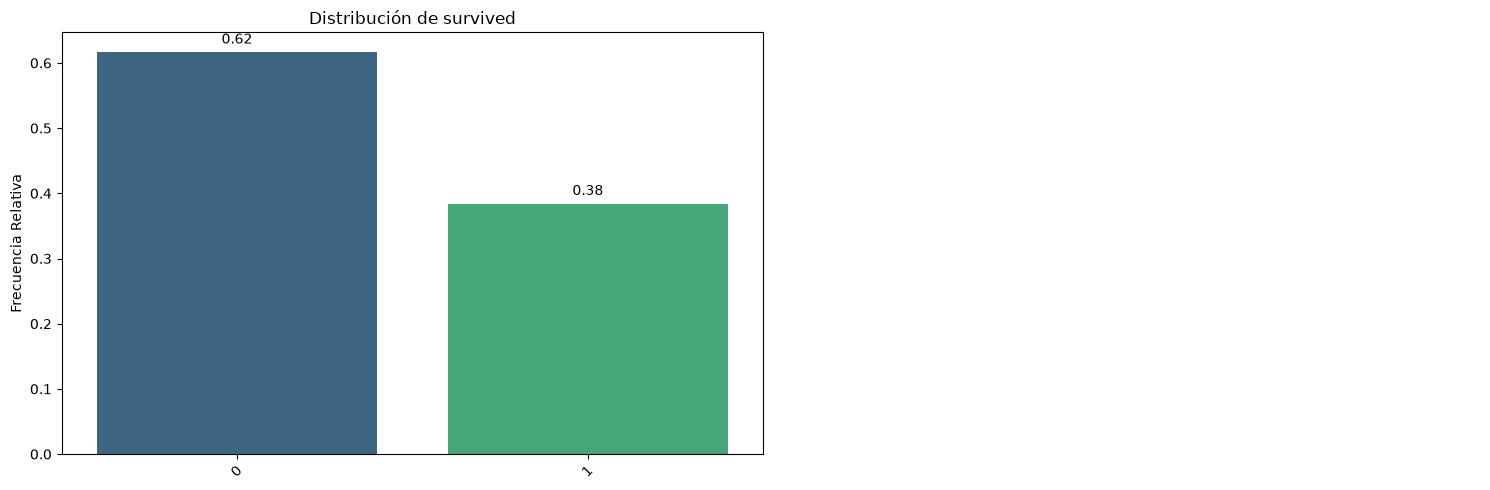

In [15]:
pinta_distribucion_categoricas(df_titanic, ["survived"], relativa=True, mostrar_valores=True)

In [16]:
# who (categórica) moda - mujeres, hombres, niños

print("Moda:", df_titanic["who"].mode()[0])
frecuencias(df_titanic, "who")

Moda: man


,Frecuencia Absoluta,Frecuencia Relativa (%)
who,,
man,537,60.27
woman,271,30.42
child,83,9.32


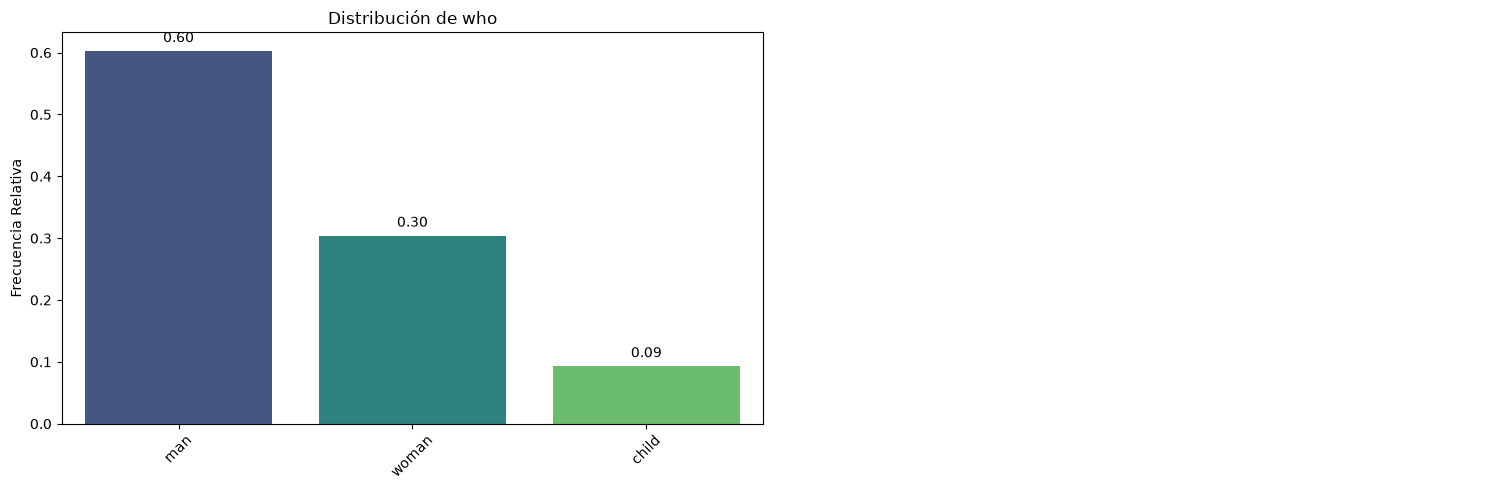

In [17]:
pinta_distribucion_categoricas(df_titanic, ["who"], relativa=True, mostrar_valores=True)

In [18]:

# sexo (masculino, femenino) - binaria

frecuencias(df_titanic, "sex")

,Frecuencia Absoluta,Frecuencia Relativa (%)
sex,,
male,577,64.76
female,314,35.24


In [19]:
# clase, categorica (moda)

print("Moda:", df_titanic["class"].mode()[0])
frecuencias(df_titanic, "class")

Moda: Third


,Frecuencia Absoluta,Frecuencia Relativa (%)
class,,
Third,491,55.11
First,216,24.24
Second,184,20.65


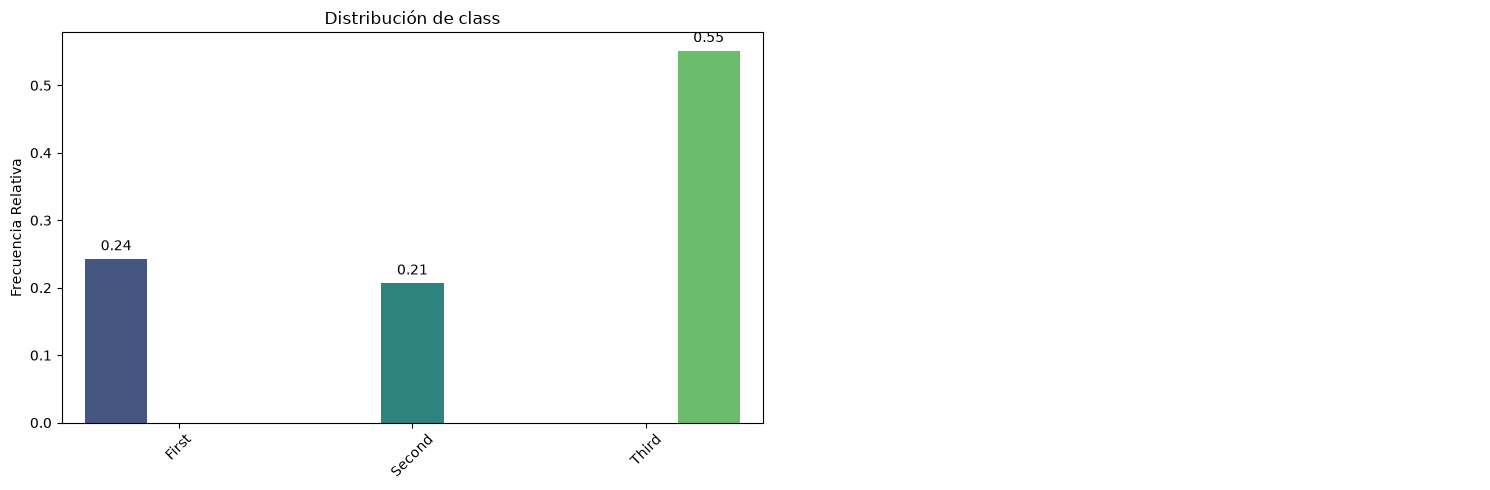

In [20]:
pinta_distribucion_categoricas(df_titanic, ["class"], relativa=True, mostrar_valores=True)

In [21]:
# embarque, categorica

print("Moda:", df_titanic["embarked"].mode()[0])
frecuencias(df_titanic, "embarked")

Moda: Southampton


,Frecuencia Absoluta,Frecuencia Relativa (%)
embarked,,
Southampton,646,72.50
Cherbourg,168,18.86
Queenstown,77,8.64


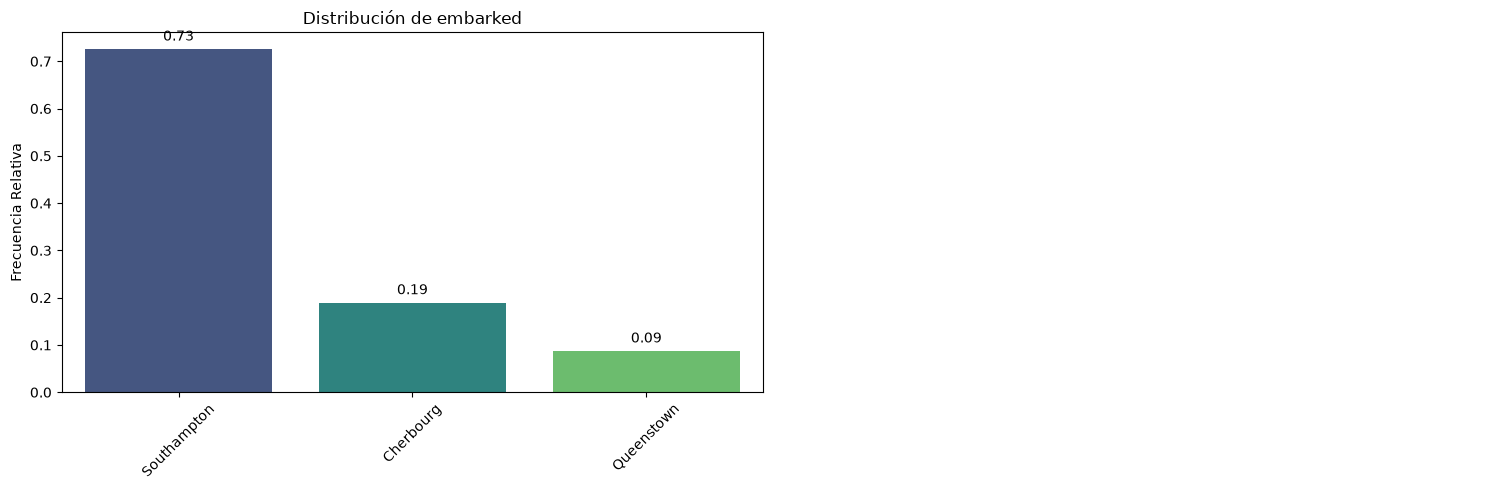

In [22]:
pinta_distribucion_categoricas(df_titanic, ["embarked"], relativa=True, mostrar_valores=True)

In [23]:
# alone, binaria 
 
print("Moda:", df_titanic["alone"].mode()[0])
frecuencias(df_titanic, "alone")

Moda: True


,Frecuencia Absoluta,Frecuencia Relativa (%)
alone,,
True,537,60.27
False,354,39.73


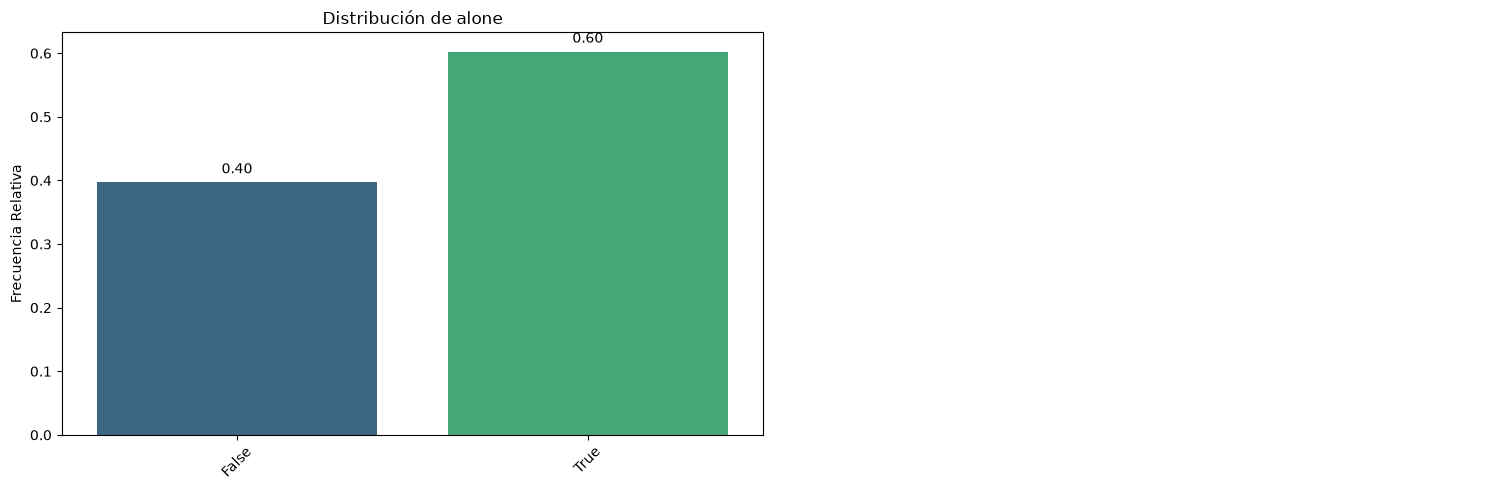

In [24]:
pinta_distribucion_categoricas(df_titanic, ["alone"], relativa=True, mostrar_valores=True)

### #2.2 Numéricas

In [26]:
def get_CV(df, columna):
    columna = [columna] if type(columna) == str else columna
    return df[columna].describe().T["std"] / df[columna].describe().T["mean"] * 100

def outliers_iqr(serie, whisker=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - whisker * iqr, q3 + whisker * iqr
    return lim_inf, lim_sup, serie[(serie < lim_inf) | (serie > lim_sup)]

num_cols = ["age", "fare"]
resumen = df_titanic[num_cols].describe().T
resumen["moda"] = [df_titanic[c].mode()[0] for c in num_cols]
resumen["CV (%)"] = get_CV(df_titanic, num_cols)
resumen["asimetria"] = df_titanic[num_cols].skew()
resumen["curtosis"] = df_titanic[num_cols].kurt()
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,moda,CV (%),asimetria,curtosis
age,891.0,29.76,13.00,0.42,22.00,30.00,35.0,80.00,30.00,43.69,0.42,0.96
fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33,8.05,154.31,4.79,33.40


(2,)


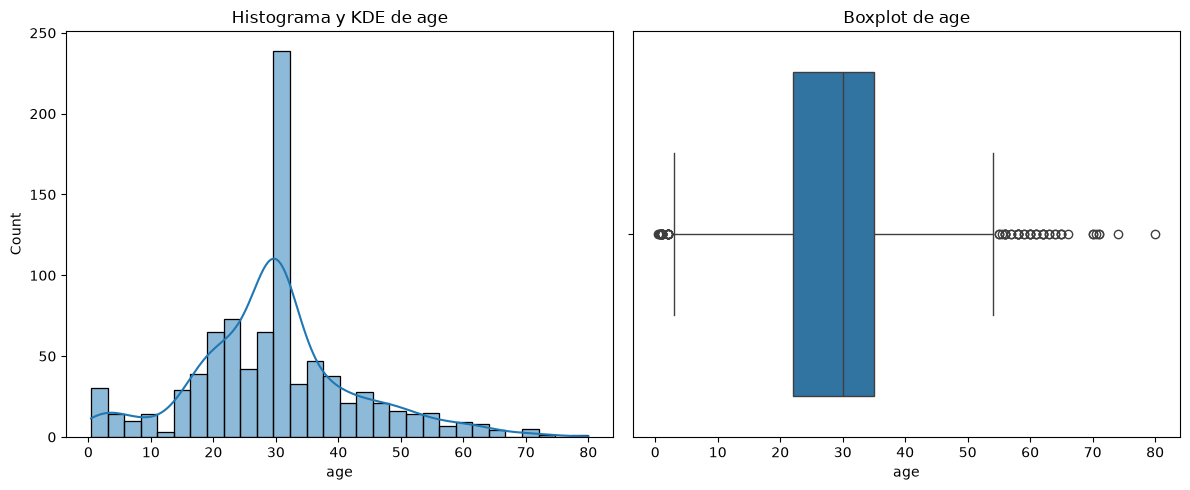

In [27]:
# edad

plot_combined_graphs(df_titanic, ["age"], bins=30)

In [28]:
lim_inf, lim_sup, out_age = outliers_iqr(df_titanic["age"])
print(f"Límites de los bigotes: {lim_inf:.1f} - {lim_sup:.1f} años")
print("Nº de outliers:", len(out_age))
print("Valores outliers (ordenados):", sorted(float(x) for x in out_age.round(1).unique()))

Límites de los bigotes: 2.5 - 54.5 años
Nº de outliers: 66
Valores outliers (ordenados): [0.4, 0.7, 0.8, 0.9, 1.0, 2.0, 55.0, 55.5, 56.0, 57.0, 58.0, 59.0, 60.0, 61.0, 62.0, 63.0, 64.0, 65.0, 66.0, 70.0, 70.5, 71.0, 74.0, 80.0]


(2,)


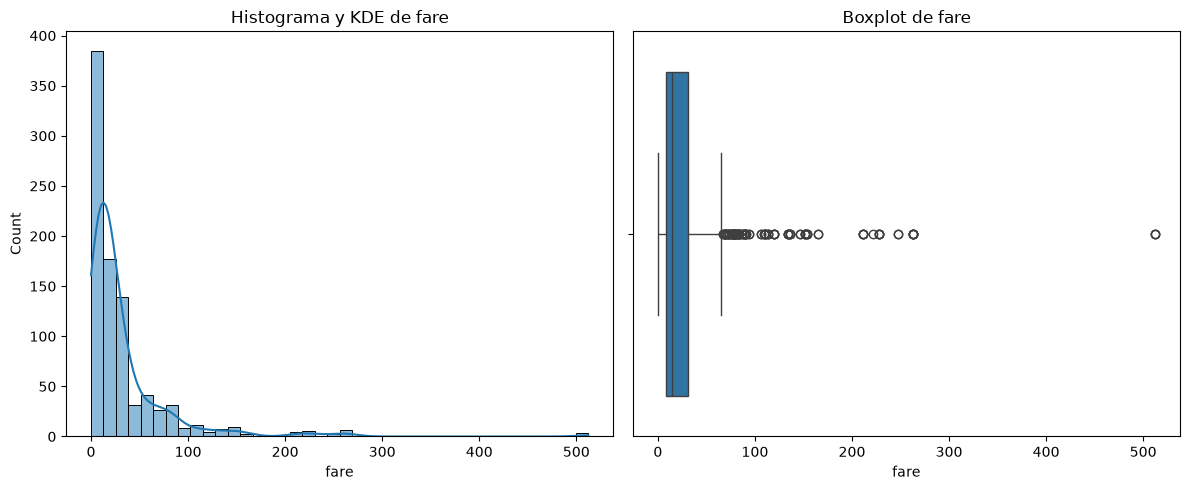

In [29]:
# tarifa

plot_combined_graphs(df_titanic, ["fare"], bins=40)

In [30]:
lim_inf, lim_sup, out_fare = outliers_iqr(df_titanic["fare"])
print(f"Límite superior del bigote: {lim_sup:.2f}")
print("Nº de outliers:", len(out_fare))
print("Pasajeros con billete a 0:", (df_titanic["fare"] == 0).sum())
print("Billete más caro:", df_titanic["fare"].max())

Límite superior del bigote: 65.63
Nº de outliers: 116
Pasajeros con billete a 0: 15
Billete más caro: 512.3292


Asimetría fare: 4.79 | Asimetría log_fare: 0.39
(2,)


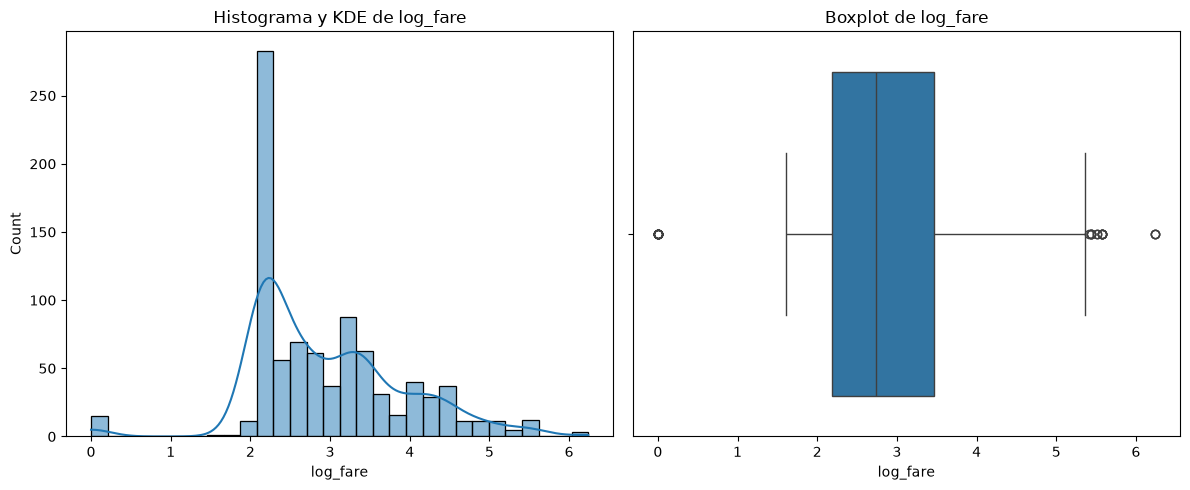

In [31]:
df_titanic["log_fare"] = np.log1p(df_titanic["fare"])
print("Asimetría fare:", round(df_titanic["fare"].skew(), 2), "| Asimetría log_fare:", round(df_titanic["log_fare"].skew(), 2))
plot_combined_graphs(df_titanic, ["log_fare"], bins=30)

In [32]:
# acompañantes, hermanos-conyuges
# numerica discreta

print(df_titanic["sibsp"].describe().round(2))
frecuencias(df_titanic, "sibsp")

count    891.00
mean       0.52
std        1.10
min        0.00
25%        0.00
50%        0.00
75%        1.00
max        8.00
Name: sibsp, dtype: float64


,Frecuencia Absoluta,Frecuencia Relativa (%)
sibsp,,
0,608,68.24
1,209,23.46
2,28,3.14
4,18,2.02
3,16,1.80
8,7,0.79
5,5,0.56


### Conclusiones tras realizar el análisis univariante

| Variable | Tipo | Valor representativo | Observación clave |
|---|---|---|---|
| `survived` | Binaria | Moda 0 (61,6 %) | Solo sobrevivió el 38,4 %. Es la tasa de referencia |
| `who` | Categórica | Moda *man* (60,3 %) | El doble de hombres que de mujeres; niños 9,3 % |
| `class` | Categórica ordinal | Moda *Third* (55,1 %) | Más pasajeros de 1ª que de 2ª |
| `embarked` | Categórica | Moda *Southampton* (72,5 %) | Puerto de salida |
| `alone` | Binaria | Moda *True* (60,3 %) | La mayoría viajaba solo |
| `age` | Numérica continua | Mediana 30 | Bastante simétrica|
| `fare` | Numérica continua | Mediana 14,45 | Asimétrica  |
